# Solvencia agregada y sensibilidad de capital: contexto para ICAAP

## Pregunta para comité
¿Cuánto cambiaría una razón agregada de solvencia si un shock de pérdida fuese absorbido íntegramente por el capital técnico y el denominador permaneciera fijo? Los estados observados son **agregados sectoriales SFC**, no un balance de entidad. Las pérdidas adicionales y reglas de transmisión son supuestos; no constituyen un ICAAP.

Se analiza la evolución de solvencia y luego se comparan escenarios sin shock, con un shock de referencia y con el doble. El objetivo del cálculo es ilustrar orden de magnitud y decisiones de información, no determinar cumplimiento ni capital requerido.

## Resultado de este corte

La razón agregada observada fue 17,156 % en junio de 2026. Bajo el supuesto de absorber por completo un shock adicional igual al mayor deterioro trimestral de la serie, con denominador fijo, la razón ilustrativa sería 16,300 %. Los universos de las dos fuentes no son idénticos y el cálculo no valida la transmisión real a capital.

## Datos, trazabilidad y alcance
El [companion SFC](../../../07-financial-and-construction-risk-lab/01-corporate-financial-risk/07-enterprise-economic-capital/observed-sfc-capital-loss-context/README.md) documenta extracción, fuente y hashes. El archivo trimestral integra capital técnico y denominador de solvencia por un lado e información agregada de deterioro contable por otro. Sus poblaciones no son idénticas y no se realiza unión por entidad. La serie cubre 2021–2026; el deterioro trimestral puede ser negativo por reversos y no es pérdida de capital económico.

[Basilea, principios de pruebas de estrés](https://www.bis.org/bcbs/publ/d450.htm) explica el uso de escenarios y gobierno; la aplicación siguiente no acredita cumplimiento. Todos los montos están en COP, salvo donde se indica.

In [1]:
from pathlib import Path
import hashlib,pandas as pd,numpy as np,matplotlib.pyplot as plt
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'03-financial-risk').is_dir())
p=root/'03-financial-risk/07-financial-and-construction-risk-lab/01-corporate-financial-risk/07-enterprise-economic-capital/observed-sfc-capital-loss-context/results/quarterly_capital_and_impairment_context.csv'
print('SHA-256:',hashlib.sha256(p.read_bytes()).hexdigest());d=pd.read_csv(p);d['fecha']=pd.PeriodIndex(d.period,freq='Q').to_timestamp(how='end').normalize();d=d.sort_values('fecha')
cols=['technical_capital_cop','total_risk_weighted_denominator_cop','weighted_aggregate_total_solvency_pct','net_impairment_expense_quarter_cop']
assert d.fecha.is_unique and d[cols].notna().all().all() and (d.total_risk_weighted_denominator_cop>0).all()
print('Trimestres:',len(d),'| periodo:',d.fecha.min().date(),d.fecha.max().date());d[['period','reporting_entities','entities_with_all_capital_components']].tail()

SHA-256: fa1a1747003c243f75598b054a0f73379a501b89fff02e217fcdeed373d82937
Trimestres: 22 | periodo: 2021-03-31 2026-06-30


,period,reporting_entities,entities_with_all_capital_components
17,2025-06,55,55
18,2025-09,55,55
19,2025-12,56,56
20,2026-03,56,56
21,2026-06,57,57


## Calidad y conciliación
Recalculamos razón agregada como capital técnico sobre denominador; la mediana por entidad responde a otra pregunta y no es el cociente del agregado. Se reporta cobertura de componentes en cada corte. Los importes y exposiciones no corresponden a una sola entidad.

In [2]:
d['ratio_recalculado']=100*d.technical_capital_cop/d.total_risk_weighted_denominator_cop
d['diferencia_pp']=d.ratio_recalculado-d.weighted_aggregate_total_solvency_pct
d['cobertura']=d.entities_with_all_capital_components/d.reporting_entities
print('Máxima discrepancia absoluta (pp):',d.diferencia_pp.abs().max());print('Cobertura mínima de componentes:',d.cobertura.min());assert d.diferencia_pp.abs().max()<0.001
d[['period','weighted_aggregate_total_solvency_pct','median_entity_reported_total_solvency_pct','cobertura']].tail()

Máxima discrepancia absoluta (pp): 4.795385919464934e-07
Cobertura mínima de componentes: 0.9565217391304348


,period,weighted_aggregate_total_solvency_pct,median_entity_reported_total_solvency_pct,cobertura
17,2025-06,16.925186,17.930,1.0
18,2025-09,17.829530,18.230,1.0
19,2025-12,17.811984,18.835,1.0
20,2026-03,17.081648,18.700,1.0
21,2026-06,17.156216,17.830,1.0


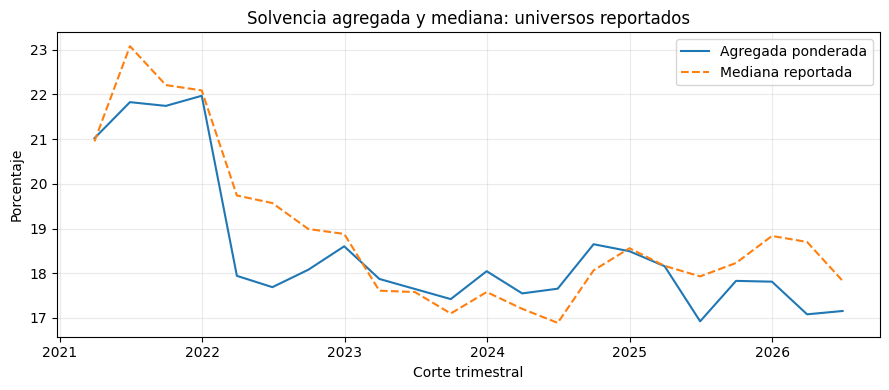

In [3]:
fig,ax=plt.subplots(figsize=(9,4));ax.plot(d.fecha,d.weighted_aggregate_total_solvency_pct,label='Agregada ponderada');ax.plot(d.fecha,d.median_entity_reported_total_solvency_pct,label='Mediana reportada',ls='--');ax.set(title='Solvencia agregada y mediana: universos reportados',xlabel='Corte trimestral',ylabel='Porcentaje');ax.grid(alpha=.25);ax.legend();plt.tight_layout();plt.show()

## Escenarios de absorción de pérdidas
Usamos el máximo deterioro contable trimestral positivo observado en el archivo como **escala de escenario** y no como pérdida futura estimada. Para multiplicadores 0, 1 y 2, suponemos que la pérdida adicional reduce capital técnico peso a peso, sin impuestos, provisiones previas, recuperación, coberturas ni cambios en activos ponderados. Esta es una hipótesis severamente simplificada: la partida de deterioro y el capital provienen de poblaciones no idénticas. No debe añadirse el deterioro histórico a capital como si se identificara su transmisión real.

In [4]:
reference=max(float(d.net_impairment_expense_quarter_cop.max()),0.0); last=d.iloc[-1]; denom=float(last.total_risk_weighted_denominator_cop);cap=float(last.technical_capital_cop)
print('Último corte:',last.period,'| escala máxima de deterioro trimestral, billones COP:',reference/1e12)
rows=[]
for mult in [0,1,2]:
    loss=mult*reference; post=cap-loss;rows.append({'multiplicador':mult,'perdida_supuesta_billones_COP':loss/1e12,'capital_hipotetico_billones_COP':post/1e12,'ratio_hipotetico_pct':100*post/denom,'variacion_pp':-100*loss/denom})
scenarios=pd.DataFrame(rows);assert (np.diff(scenarios.ratio_hipotetico_pct)<=0).all();scenarios.round(3)

Último corte: 2026-06 | escala máxima de deterioro trimestral, billones COP: 6.627855126022998


,multiplicador,perdida_supuesta_billones_COP,capital_hipotetico_billones_COP,ratio_hipotetico_pct,variacion_pp
0,0,0.000,132.753,17.156,-0.000
1,1,6.628,126.125,16.300,-0.857
2,2,13.256,119.497,15.443,-1.713


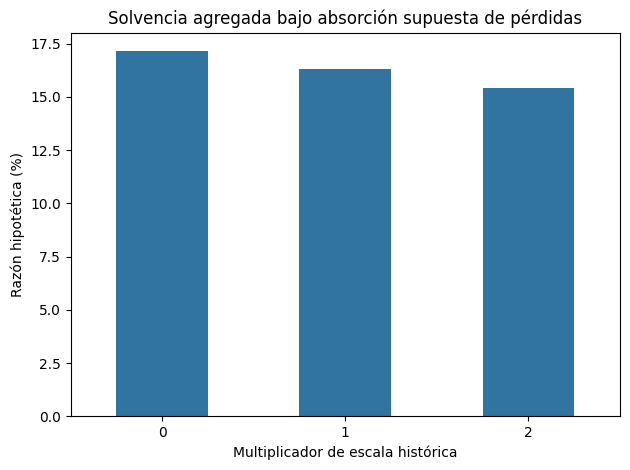

In [5]:
ax=scenarios.plot.bar(x='multiplicador',y='ratio_hipotetico_pct',legend=False,color='#3274a1',title='Solvencia agregada bajo absorción supuesta de pérdidas');ax.set(xlabel='Multiplicador de escala histórica',ylabel='Razón hipotética (%)');ax.tick_params(axis='x',rotation=0);ax.set_ylim(bottom=0);plt.tight_layout();plt.show()

## Decisión y validación necesaria
La comparación ayuda a priorizar un análisis de sensibilidad con balances y escenarios propios. Para ICAAP real se necesitan capital disponible por entidad, composición y elegibilidad, proyecciones financieras, estrategias de gestión, riesgos materiales, cambios de denominador, horizontes, umbrales aprobados y validación independiente. El escenario ilustrativo no evalúa umbrales regulatorios ni estima probabilidad de insolvencia.